# Vorstudie: Übersichtstabelle

Fasst die vier Vorstudien-Notebooks in einer Tabelle zusammen und exportiert sie als PNG und PDF nach `results/prestudy/`. Das Notebook liest nur die fertigen CSVs aus `results/prestudy/`, es wird nichts trainiert. Ein Durchlauf dauert wenige Sekunden.

**Spalten** (n = 1000, noise = 0.5, Mittel über die Refits):
- **Regret:** normierter Regret auf der Testmenge, MSE-Modell / SPO+-Modell
- **ΔMSE-Anteil der Ablenker:** Anteil der Ablenker-Features an der Summe der (bei 0 abgeschnittenen) skalenbereinigten ΔMSE-Werte, MSE / SPO+ / wahre Kostenfunktion E[c | x]
- **ΔRegret-Anteil von x1, x2:** Anteil der kritischen Features an der Summe der ΔRegret-Werte, MSE / SPO+

Beim PyEPO-Generator gibt es keine festgelegten Feature-Rollen, die Anteile entfallen dort.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

import prestudy as v

N, NOISE = 1000, 0.5
data = {(p, d): pd.read_csv(v.result_path(p, d))
        for p in ("shortest_path", "knapsack") for d in ("pyepo", "planted")}

In [2]:
def select(df, deg, size=None):
    """Zeilen einer Einstellung: trainierte Modelle mit n = N, wahre Kostenfunktion ohne n."""
    sub = df[(df.deg == deg) & (df.noise == NOISE) & ((df.n == N) | (df.loss == "oracle"))]
    return sub if size is None else sub[sub["size"] == size]


def regret(df, deg, size=None):
    """Mittlerer normierter Regret je Loss."""
    perf = v.performance(select(df, deg, size))
    return perf.groupby("loss").regret.mean()


def share(df, measure, feats, deg, size=None):
    """Anteil der Features feats an der Summe der bei 0 abgeschnittenen PFI-Werte, je Refit, dann gemittelt."""
    sub = select(df, deg, size).copy()
    sub["val"] = sub[measure].clip(lower=0)
    sub["part"] = sub.val.where(sub.feature.isin(feats), 0)
    g = sub.groupby(["loss", "refit"])[["part", "val"]].sum()
    return (g.part / g.val).groupby("loss").mean()


def num(x):
    """Deutsche Schreibweise, bei sehr kleinen Werten eine Stelle mehr."""
    return (f"{x:.3f}" if abs(x) < 0.01 else f"{x:.2f}").replace(".", ",")


def pair(s, keys=("mse", "spo+"), digits=None):
    return " / ".join(f"{s[k]:.{digits}f}".replace(".", ",") if digits else num(s[k]) for k in keys)

In [3]:
ALL = ("mse", "spo+", "oracle")
rows = []
for label, key, size, structure in [
    ("Shortest Path 5×5\nPyEPO", ("shortest_path", "pyepo"), None, "B zufällig,\nalle 5 Features wirken"),
    ("Knapsack 32 Items\nPyEPO", ("knapsack", "pyepo"), None, "B zufällig,\nalle 5 Features wirken"),
    ("Shortest Path 5×5\nplanted", ("shortest_path", "planted"), 5, "x1, x2 kritisch; x3, x4 Ablenker;\nx5 Rauschen"),
    ("Shortest Path 10×10\nplanted", ("shortest_path", "planted"), 10, "wie 5×5"),
    ("Knapsack 32 Items\nplanted", ("knapsack", "planted"), None, "x1, x2 kritisch; x3 „zu schwer“,\nx4 „gratis“; x5 Rauschen"),
]:
    df = data[key]
    row = {"Studie": label, "Datenstruktur": structure,
           "Regret, deg 1\nMSE / SPO+": pair(regret(df, 1, size), digits=3),
           "Regret, deg 6\nMSE / SPO+": pair(regret(df, 6, size), digits=3)}
    if key[1] == "pyepo":
        row["ΔMSE-Anteil Ablenker, deg 6\nMSE / SPO+ / wahr"] = "keine Grundwahrheit"
        row["ΔRegret-Anteil x1, x2, deg 6\nMSE / SPO+"] = "keine Grundwahrheit"
    else:
        if key[0] == "knapsack":
            dist = "\n".join(f"{name}: {pair(share(df, 'd_mse_adj', [f], 6, size), ALL)}"
                             for name, f in (("x3", "x3"), ("x4", "x4")))
        else:
            dist = pair(share(df, "d_mse_adj", ["x3", "x4"], 6, size), ALL)
        row["ΔMSE-Anteil Ablenker, deg 6\nMSE / SPO+ / wahr"] = dist
        row["ΔRegret-Anteil x1, x2, deg 6\nMSE / SPO+"] = pair(share(df, "d_regret", ["x1", "x2"], 6, size))
    rows.append(row)

table = pd.DataFrame(rows)
table

,Studie,Datenstruktur,"Regret, deg 1\nMSE / SPO+","Regret, deg 6\nMSE / SPO+","ΔMSE-Anteil Ablenker, deg 6\nMSE / SPO+ / wahr","ΔRegret-Anteil x1, x2, deg 6\nMSE / SPO+"
0,Shortest Path 5×5\nPyEPO,"B zufällig,\nalle 5 Features wirken","0,154 / 0,155","0,124 / 0,069",keine Grundwahrheit,keine Grundwahrheit
1,Knapsack 32 Items\nPyEPO,"B zufällig,\nalle 5 Features wirken","0,112 / 0,114","0,148 / 0,082",keine Grundwahrheit,keine Grundwahrheit
2,Shortest Path 5×5\nplanted,"x1, x2 kritisch; x3, x4 Ablenker;\nx5 Rauschen","0,064 / 0,064","0,085 / 0,026","0,13 / 0,10 / 0,07","1,00 / 1,00"
3,Shortest Path 10×10\nplanted,wie 5×5,"0,031 / 0,031","0,068 / 0,015","0,25 / 0,16 / 0,15","1,00 / 1,00"
4,Knapsack 32 Items\nplanted,"x1, x2 kritisch; x3 „zu schwer“,\nx4 „gratis“;...","0,095 / 0,098","0,036 / 0,026","x3: 0,16 / 0,005 / 0,16\nx4: 0,16 / 0,12 / 0,17","0,92 / 0,99"


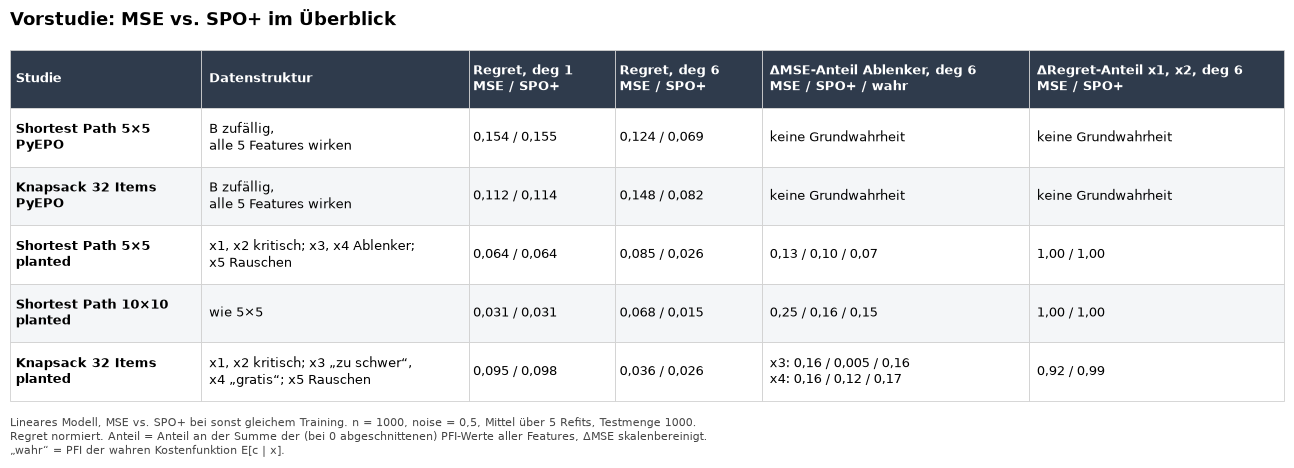

gespeichert:
/Users/anton/Desktop/WiSe26-27/Aktuelle Forschungsfragen des Operations Research/FeatureSelection-XAI-SPOPlus-MSE/results/prestudy/prestudy_summary_table.png
/Users/anton/Desktop/WiSe26-27/Aktuelle Forschungsfragen des Operations Research/FeatureSelection-XAI-SPOPlus-MSE/results/prestudy/prestudy_summary_table.pdf
/Users/anton/Desktop/WiSe26-27/Aktuelle Forschungsfragen des Operations Research/FeatureSelection-XAI-SPOPlus-MSE/results/prestudy/prestudy_summary_table.csv


In [4]:
FOOTNOTE = ("Lineares Modell, MSE vs. SPO+ bei sonst gleichem Training. n = 1000, noise = 0,5, Mittel über 5 Refits, "
            "Testmenge 1000.\nRegret normiert. Anteil = Anteil an der Summe der (bei 0 abgeschnittenen) PFI-Werte aller Features, "
            "ΔMSE skalenbereinigt.\n„wahr“ = PFI der wahren Kostenfunktion E[c | x].")
WIDTHS = [0.15, 0.21, 0.115, 0.115, 0.21, 0.20]


def render(table, path_stem):
    """Tabelle als Bild: alle Zeilen zweizeilig, Kopf dunkel, Zeilen abwechselnd hinterlegt."""
    n_rows = len(table) + 1
    fig = plt.figure(figsize=(13, 0.62 * n_rows + 1.3))
    ax = fig.add_axes([0.01, 0.20, 0.98, 0.70])
    ax.axis("off")
    tab = ax.table(cellText=table.values, colLabels=table.columns, colWidths=WIDTHS,
                   cellLoc="left", colLoc="left", bbox=[0, 0, 1, 1])
    tab.auto_set_font_size(False)
    tab.set_fontsize(9.5)
    for (r, c), cell in tab.get_celld().items():
        cell.set_edgecolor("#d0d0d0")
        cell.set_linewidth(0.6)
        cell.PAD = 0.03
        if r == 0:
            cell.set_facecolor("#2f3b4c")
            cell.get_text().set_color("white")
            cell.get_text().set_fontweight("bold")
        else:
            cell.set_facecolor("#f4f6f8" if r % 2 == 0 else "white")
            if c == 0:
                cell.get_text().set_fontweight("bold")
    fig.text(0.01, 0.94, "Vorstudie: MSE vs. SPO+ im Überblick", fontsize=13, fontweight="bold", va="bottom")
    fig.text(0.01, 0.17, FOOTNOTE, fontsize=8, color="#444444", va="top")
    for ext in ("png", "pdf"):
        fig.savefig(v.RESULTS / f"{path_stem}.{ext}", dpi=200, bbox_inches="tight")
    plt.show()


render(table, "prestudy_summary_table")
table.to_csv(v.RESULTS / "prestudy_summary_table.csv", index=False)
print("gespeichert:", *(v.RESULTS / f"prestudy_summary_table.{e}" for e in ("png", "pdf", "csv")), sep="\n")